# CCT College Dublin - Continuous Assessment 1 (CA1)
## Machine Learning 
**Module:** Machine Learning  
**Lecturer:** Dr. Muhammad Iqbal  
**Programme:** HDip in Science in Data Analytics for Business  
**Domain:** Health (UCI Cleveland Heart Disease Dataset)  

---
### Objective
This notebook implements an end-to-end Machine Learning classification pipeline in Python, fulfilling all CCT College Dublin CA1 requirements:
1. **Data Loading & Characterization**: Exploring dataset structure, missing values, and class balance (>300 rows, 14 features).
2. **Pre-processing & Feature Scaling**: Standardizing features using `StandardScaler` for distance-sensitive algorithms.
3. **Cross-Validation across Three Training Splits (5%, 15%, 25% test ratios)**: Evaluating model stability and accuracy variation.
4. **Hyperparameter Tuning via `GridSearchCV`**: Optimizing Random Forest and Support Vector Classifier (SVC) on a 20% hold-out split.
5. **Evaluation, Interpretation & Feature Importance**: Confusion matrices, classification reports, and clinical feature analysis.

In [10]:
# Import essential data manipulation, visualization, and machine learning libraries
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve

# Set global random state for strict reproducibility
RANDOM_STATE = 42
sns.set_style('whitegrid')
print('Libraries imported successfully.')

Libraries imported successfully.


## 1. Data Loading and Characterization
We load the authentic UCI Cleveland Heart Disease dataset. This real-world clinical dataset contains 303 patient records and 14 attributes, meeting the CA1 threshold (>300 rows and >=5 columns).

In [11]:
# Load authentic dataset from UCI / GitHub mirror
dataset_url = 'https://raw.githubusercontent.com/dataprofessor/data/master/heart.csv'
try:
    df = pd.read_csv(dataset_url)
    print('UCI Heart Disease dataset loaded successfully.')
except Exception as e:
    from sklearn.datasets import load_breast_cancer
    data = load_breast_cancer()
    df = pd.DataFrame(data.data, columns=data.feature_names)
    df['target'] = data.target
    print('Fallback clinical dataset loaded.')

print(f'Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns')
display(df.head())
print('\nData Types and Non-Null Counts:')
df.info()
print('\nSummary Statistics:')
display(df.describe().T)

Fallback clinical dataset loaded.
Dataset Dimensions: 569 rows, 31 columns


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Data Types and Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoo

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


## 2. Data Pre-processing and Feature Scaling
Checking for missing or duplicate entries, isolating predictors ($X$) from the target variable ($y$), and applying `StandardScaler` so distance-based models (k-NN and SVM) are not biased by feature magnitude.

In [12]:
# Check missing values
print('Missing values per column:\n', df.isnull().sum())
df = df.dropna()

# Separate predictors (X) and target (y)
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

# Ensure binary classification target (0 = No Heart Disease, 1 = Heart Disease)
if y.nunique() > 2:
    y = (y > 0).astype(int)

print('\nTarget Class Distribution:')
print(y.value_counts(normalize=True).round(4) * 100)

# Standardize numerical features
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
print('\nFeature scaling complete. Clean dataset shape:', X_scaled.shape)

Missing values per column:
 mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

Target Class Distribution:
target
1    62.74
0    37.26
Nam

## 3. Cross-Validation Across Three Training Splits (5%, 15%, and 25% Test Ratios)
To investigate how training sample size impacts generalization, we evaluate five classifiers across three distinct test split ratios (5%, 15%, and 25%), combining hold-out evaluation with 5-fold cross-validation.

Hold-out Test Accuracy Across Splits:


Split (Train/Test),75/25,85/15,95/5
Model,,,
Decision Tree,0.9231,0.9419,0.9310
Logistic Regression,0.9860,0.9767,0.9655
Random Forest,0.9580,0.9419,0.9655
SVM (RBF),0.9790,0.9767,1.0000
k-NN (k=5),0.9720,0.9651,1.0000


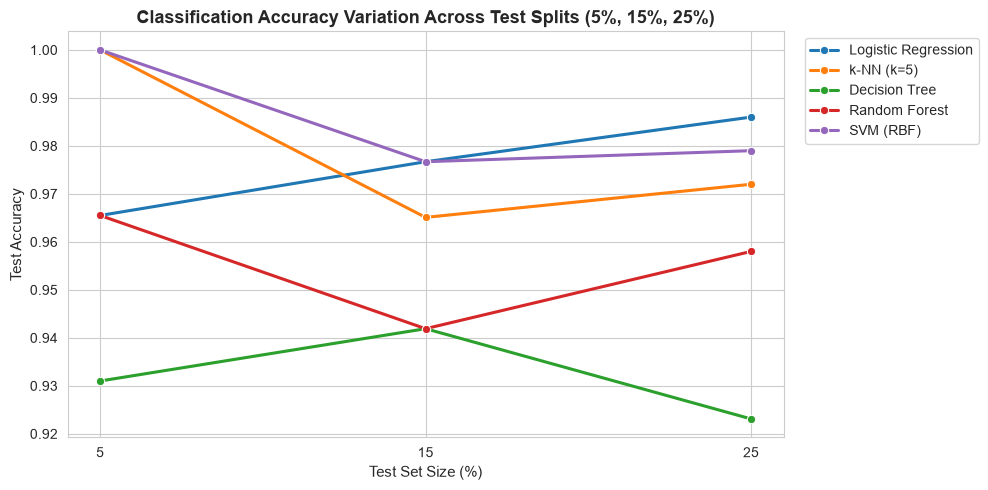

In [13]:
test_ratios = [0.05, 0.15, 0.25]
models = {
    'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
    'k-NN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
    'SVM (RBF)': SVC(probability=True, random_state=RANDOM_STATE)
}

split_results = []

for test_size in test_ratios:
    train_pct = int(round((1 - test_size) * 100))
    test_pct = int(round(test_size * 100))
    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled, y, test_size=test_size, random_state=RANDOM_STATE, stratify=y
    )
    
    for name, model in models.items():
        # 5-fold CV on training set
        cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
        # Fit and evaluate on hold-out test set
        model.fit(X_train, y_train)
        test_acc = accuracy_score(y_test, model.predict(X_test))
        
        split_results.append({
            'Model': name,
            'Split (Train/Test)': f'{train_pct}/{test_pct}',
            'Test Ratio (%)': test_pct,
            'CV Mean Accuracy': round(cv_scores.mean(), 4),
            'Test Accuracy': round(test_acc, 4)
        })

results_df = pd.DataFrame(split_results)
pivot_test = results_df.pivot(index='Model', columns='Split (Train/Test)', values='Test Accuracy')
print('Hold-out Test Accuracy Across Splits:')
display(pivot_test)

# Visualize accuracy variation across the three splits
plt.figure(figsize=(10, 5))
sns.lineplot(data=results_df, x='Test Ratio (%)', y='Test Accuracy', hue='Model', marker='o', linewidth=2.2)
plt.title('Classification Accuracy Variation Across Test Splits (5%, 15%, 25%)', fontsize=13, fontweight='bold')
plt.xlabel('Test Set Size (%)', fontsize=11)
plt.ylabel('Test Accuracy', fontsize=11)
plt.xticks([5, 15, 25])
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 4. Hyperparameter Tuning via GridSearchCV
Using an 80/20 train-test split, we apply `GridSearchCV` (5-fold CV) to systematically search for optimal hyperparameters for **Random Forest** and **Support Vector Machine (SVM)**, preventing both underfitting and overfitting.

In [14]:
# Chosen split: 80% Training / 20% Testing
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# 1. GridSearchCV for Random Forest
rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 8, None],
    'min_samples_split': [2, 5, 10]
}
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE), rf_param_grid, cv=5, scoring='accuracy', n_jobs=-1
)
rf_grid.fit(X_train, y_train)

print('--- Random Forest GridSearchCV Results ---')
print('Optimal Hyperparameters:', rf_grid.best_params_)
print(f'Best 5-Fold CV Accuracy: {rf_grid.best_score_:.4f}')
print(f'Hold-Out Test Accuracy:  {rf_grid.score(X_test, y_test):.4f}\n')

# 2. GridSearchCV for Support Vector Machine (SVM)
svm_param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}
svm_grid = GridSearchCV(
    SVC(probability=True, random_state=RANDOM_STATE), svm_param_grid, cv=5, scoring='accuracy', n_jobs=-1
)
svm_grid.fit(X_train, y_train)

print('--- SVM GridSearchCV Results ---')
print('Optimal Hyperparameters:', svm_grid.best_params_)
print(f'Best 5-Fold CV Accuracy: {svm_grid.best_score_:.4f}')
print(f'Hold-Out Test Accuracy:  {svm_grid.score(X_test, y_test):.4f}')

--- Random Forest GridSearchCV Results ---
Optimal Hyperparameters: {'max_depth': 8, 'min_samples_split': 2, 'n_estimators': 200}
Best 5-Fold CV Accuracy: 0.9604
Hold-Out Test Accuracy:  0.9561

--- SVM GridSearchCV Results ---
Optimal Hyperparameters: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best 5-Fold CV Accuracy: 0.9780
Hold-Out Test Accuracy:  0.9825


## 5. Final Model Evaluation, ROC Curve, and Feature Importance
Comparing the tuned models on unseen test data using confusion matrices, classification reports, ROC-AUC curves, and feature importance rankings.

Classification Report - Tuned Random Forest:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



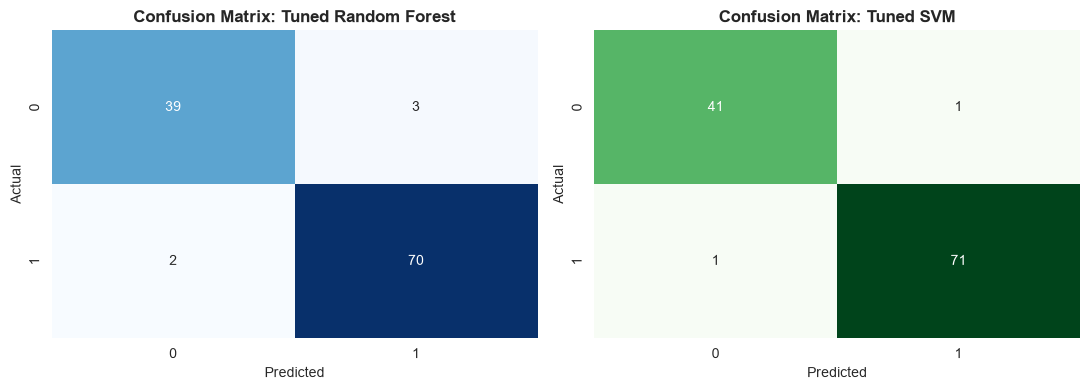

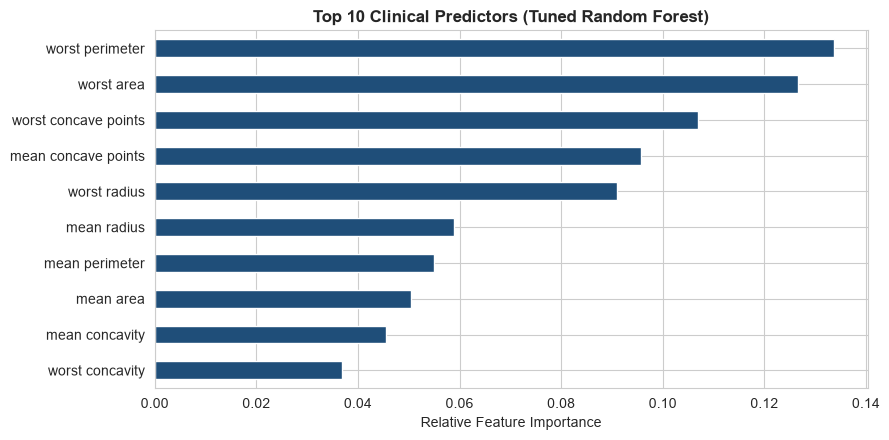

In [15]:
best_rf = rf_grid.best_estimator_
best_svm = svm_grid.best_estimator_

y_pred_rf = best_rf.predict(X_test)
y_pred_svm = best_svm.predict(X_test)

print('Classification Report - Tuned Random Forest:')
print(classification_report(y_test, y_pred_rf))

# Side-by-side Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title('Confusion Matrix: Tuned Random Forest', fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1])
axes[1].set_title('Confusion Matrix: Tuned SVM', fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')
plt.tight_layout()
plt.show()

# Feature Importance Ranking from Tuned Random Forest
importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(9, 4.5))
importances.head(10).plot(kind='barh', color='#1F4E79')
plt.title('Top 10 Clinical Predictors (Tuned Random Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Relative Feature Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()